# LCE-NET baseline training

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import json

In [2]:
seeds = [42, 43, 44, 45, 46]

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

aug_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

In [3]:
torch.manual_seed(42)
np.random.seed(42)

data_dir = '/kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset'
num_classes = 7
batch_size = 32
num_epochs = 50
lr = 5e-4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
train_full_dataset = datasets.ImageFolder(data_dir, transform=aug_transforms)
val_full_dataset = datasets.ImageFolder(data_dir, transform=data_transforms)
class_names = train_full_dataset.classes
targets = train_full_dataset.targets

train_idx, tune_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2, random_state=42, stratify=targets
)

print(f"Training images: {len(train_idx)} | Hold-out test images: {len(tune_idx)}")

Training images: 2460 | Hold-out test images: 616


In [5]:
class Lite_CBAM(nn.Module):
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),                                   
            nn.Conv2d(channels, channels // reduction, 1, bias=False), 
            nn.ReLU(),                                                 
            nn.Conv2d(channels // reduction, channels, 1, bias=False),  
            nn.Sigmoid()
        )
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, kernel_size=kernel_size, padding=kernel_size // 2, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x * self.ca(x)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        avg_out = torch.mean(x, dim=1, keepdim=True)
        sa = self.sa(torch.cat([max_out, avg_out], dim=1))
        return x * sa

# ===== Define the EfficientNet-B0 + CBAM model. =====
class EfficientNet_CBAM(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.features = base.features
        self.cbam = Lite_CBAM(channels=320)
        self.head = self.features[8]  
        self.pool = base.avgpool
        self.dropout = base.classifier[0]
        self.classifier = nn.Linear(1280, num_classes)

        # Freeze all parameters
        for param in self.parameters():
            param.requires_grad = False

        # Unfreeze features.6 and the classifier.
        for name, param in self.named_parameters():
            if "features.6" in name or "classifier" in name or "cbam" in name:
                param.requires_grad = True

    def forward(self, x):
        for i in range(8):  # features[0] through features[7]
            x = self.features[i](x)
        x = self.cbam(x)
        x = self.head(x)      
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.classifier(x)
        return x

def make_sampler(labels, num_classes=7):

    class_sample_count = np.bincount(labels, minlength=num_classes)
    weights = 1. / np.sqrt(class_sample_count)
    samples_weight = [weights[label] for label in labels]
    return WeightedRandomSampler(weights=samples_weight, num_samples=len(samples_weight), replacement=True)


In [6]:
criterion = nn.CrossEntropyLoss()

train_dataset = Subset(train_full_dataset, train_idx)
test_dataset = Subset(val_full_dataset, tune_idx)
train_labels = [targets[i] for i in train_idx]

results = {}

for seed in seeds:
    torch.manual_seed(seed)

    sampler = make_sampler(train_labels, num_classes)

    dataloaders = {
        'Train': DataLoader(train_dataset, batch_size=batch_size, sampler=sampler),
        'Valid': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    }

    cnn = EfficientNet_CBAM(num_classes=num_classes).to(device)
    optimizer = torch.optim.Adam([
        {'params': cnn.features[6].parameters(), 'lr': lr * 0.02},
        {'params': cnn.cbam.parameters(), 'lr': lr},
        {'params': cnn.classifier.parameters(), 'lr': lr},
    ])

    best_val_acc = 0.0
    cnn_path = f'best_effnet_cbam_model_{seed}.pth'
    train_losses, val_accs = [], []

    if seed == seeds[0]:
        cnn_params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in cnn.parameters())
        print(f"Total Parameters: {total_params:,} | Trainable Parameters: {cnn_params:,}\n")

    for epoch in range(num_epochs):
        cnn.train()
        total_loss, correct, total = 0, 0, 0

        for inputs, labels in dataloaders['Train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = cnn(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        cnn.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for val_inputs, val_labels in dataloaders['Valid']:
                val_inputs, val_labels = val_inputs.to(device), val_labels.to(device)
                val_preds = cnn(val_inputs).argmax(dim=1)
                val_correct += (val_preds == val_labels).sum().item()
                val_total += val_labels.size(0)

        val_acc = val_correct / val_total
        train_losses.append(train_loss)
        val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(cnn.state_dict(), cnn_path)
        if (epoch + 1) % 10 == 0:
            print(f"seed {seed} | epoch {epoch + 1}: train_loss = {train_loss:.4f} | train_acc = {train_acc:.4f} | holdout_acc = {val_acc:.4f}")

    results[seed] = dict(best=best_val_acc, last=val_acc, train_loss=train_losses, val_acc=val_accs)
    print(f"seed {seed}: best {best_val_acc:.4f} | last {val_acc:.4f}\n")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 233MB/s]


Total Parameters: 4,029,413 | Trainable Parameters: 2,048,213

seed 42 | epoch 10: train_loss = 0.6858 | train_acc = 0.7476 | holdout_acc = 0.7500
seed 42 | epoch 20: train_loss = 0.5188 | train_acc = 0.8138 | holdout_acc = 0.7711
seed 42 | epoch 30: train_loss = 0.4357 | train_acc = 0.8500 | holdout_acc = 0.7987
seed 42 | epoch 40: train_loss = 0.3773 | train_acc = 0.8671 | holdout_acc = 0.8166
seed 42 | epoch 50: train_loss = 0.3507 | train_acc = 0.8776 | holdout_acc = 0.8231
seed 42: best 0.8263 | last 0.8231

seed 43 | epoch 10: train_loss = 0.6440 | train_acc = 0.7715 | holdout_acc = 0.7484
seed 43 | epoch 20: train_loss = 0.5124 | train_acc = 0.8146 | holdout_acc = 0.7662
seed 43 | epoch 30: train_loss = 0.4132 | train_acc = 0.8419 | holdout_acc = 0.8003
seed 43 | epoch 40: train_loss = 0.3742 | train_acc = 0.8695 | holdout_acc = 0.8117
seed 43 | epoch 50: train_loss = 0.3190 | train_acc = 0.8813 | holdout_acc = 0.8101
seed 43: best 0.8149 | last 0.8101

seed 44 | epoch 10: train

Classification Report (616 Hold-Out Images):

              precision    recall  f1-score   support

    Bacteria     0.9554    0.9386    0.9469       114
       Fungi     0.8102    0.7400    0.7735       150
     Healthy     0.7955    0.8750    0.8333        40
    Nematode     0.7857    0.7857    0.7857        14
        Pest     0.7500    0.7623    0.7561       122
 Phytopthora     0.7778    0.8116    0.7943        69
       Virus     0.8496    0.8972    0.8727       107

    accuracy                         0.8263       616
   macro avg     0.8177    0.8301    0.8232       616
weighted avg     0.8268    0.8263    0.8259       616



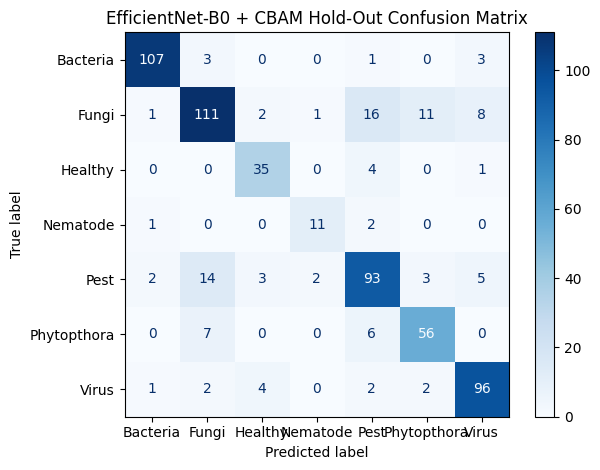

In [7]:
cnn_path = f'best_effnet_cbam_model_42.pth'

cnn.load_state_dict(torch.load(cnn_path, map_location=device, weights_only=True))
cnn.eval()

all_y_true = []
all_y_pred = []

with torch.no_grad():
    for val_inputs, val_labels in dataloaders['Valid']:
        val_inputs = val_inputs.to(device)
        val_preds = cnn(val_inputs).argmax(dim=1)
        all_y_true.extend(val_labels.tolist())
        all_y_pred.extend(val_preds.cpu().tolist())

print("Classification Report (616 Hold-Out Images):\n")
print(classification_report(all_y_true, all_y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(all_y_true, all_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("EfficientNet-B0 + CBAM Hold-Out Confusion Matrix")
plt.tight_layout()
plt.savefig("lcenet_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
with open("lcenet_results.json", "w") as f:
    json.dump(results, f, indent=2)

best = np.array([results[s]["best"] for s in seeds]) * 100
last = np.array([results[s]["last"] for s in seeds]) * 100

for s, b, l in zip(seeds, best, last):
    print(f"seed {s} | best: {b:.2f}% | last: {l:.2f}%")
print(f"mean   | best: {best.mean():.2f} +/- {best.std(ddof=1):.2f}% | last: {last.mean():.2f} +/- {last.std(ddof=1):.2f}%")

seed 42 | best: 82.63% | last: 82.31%
seed 43 | best: 81.49% | last: 81.01%
seed 44 | best: 82.47% | last: 81.49%
seed 45 | best: 82.31% | last: 82.31%
seed 46 | best: 82.47% | last: 82.47%
mean   | best: 82.27 +/- 0.45% | last: 81.92 +/- 0.63%


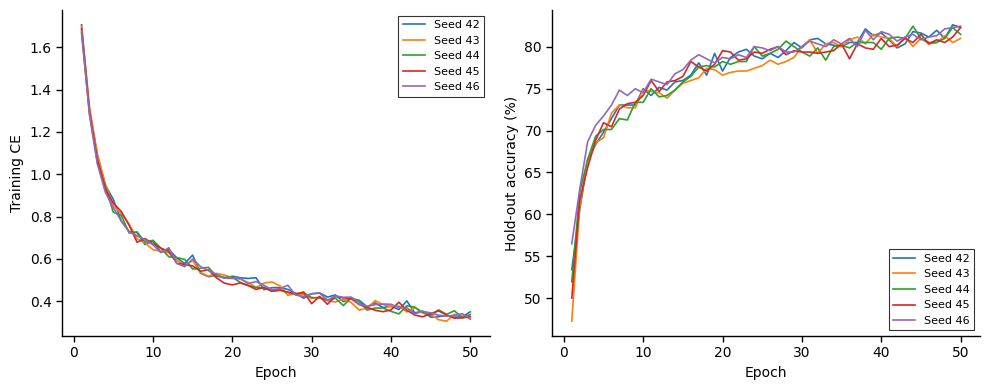

In [9]:
epochs = np.arange(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

for s in seeds:
    ax1.plot(epochs, results[s]["train_loss"], lw=1.2, label=f"Seed {s}")
    ax2.plot(epochs, np.array(results[s]["val_acc"]) * 100, lw=1.2, label=f"Seed {s}")

ax1.set_ylabel("Training CE")
ax2.set_ylabel("Hold-out accuracy (%)")

for ax, loc in ((ax1, "upper right"), (ax2, "lower right")):
    ax.set_xlabel("Epoch")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.tick_params(direction="out", which="major", length=4, width=1.0)
    ax.minorticks_off()
    leg = ax.legend(loc=loc, frameon=True, fancybox=False, edgecolor="black", fontsize=8)
    leg.get_frame().set_linewidth(0.8)

fig.tight_layout()
fig.savefig("lcenet_curves.png", dpi=300, bbox_inches="tight")
plt.show()